In [ ]:
%load_ext autoreload
%autoreload 2
%load_ext jupyter_black

import sys
from pathlib import Path

scripts_path = str(Path.cwd().parents[1]) + "/scripts/"
if scripts_path not in sys.path:
    sys.path.insert(0, scripts_path)

from Config import MPLSTYLE

import Syn_Spec_toolkit as SSt

import numpy as np
import matplotlib.pyplot as plt, matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.constants as const
from astropy.config import generate_config

generate_config(pkgname="synphot")

from sedfitter.sed import SEDCube
from synphot.models import Empirical1D
from synphot import units, SourceSpectrum
from astroquery.svo_fps import SvoFps

import matplotlib.colors as mcolors
import matplotlib.cm as cm
from tqdm import tqdm

if MPLSTYLE.exists():
    plt.style.use(str(MPLSTYLE))

### Testing our class + plotting

In [52]:
SPEC = SSt.Line_Strength(continuum_mode="Bessel")
SPEC.Add_emission_line_to_spectrum(
    lam0=SSt.wave_pa_alpha.to(u.AA),
    W_eq=1 * u.AA,
)

SPEC.Add_emission_line_to_spectrum(
    lam0=SSt.wave_br_alpha.to(u.AA),
    W_eq=1 * u.AA,
)

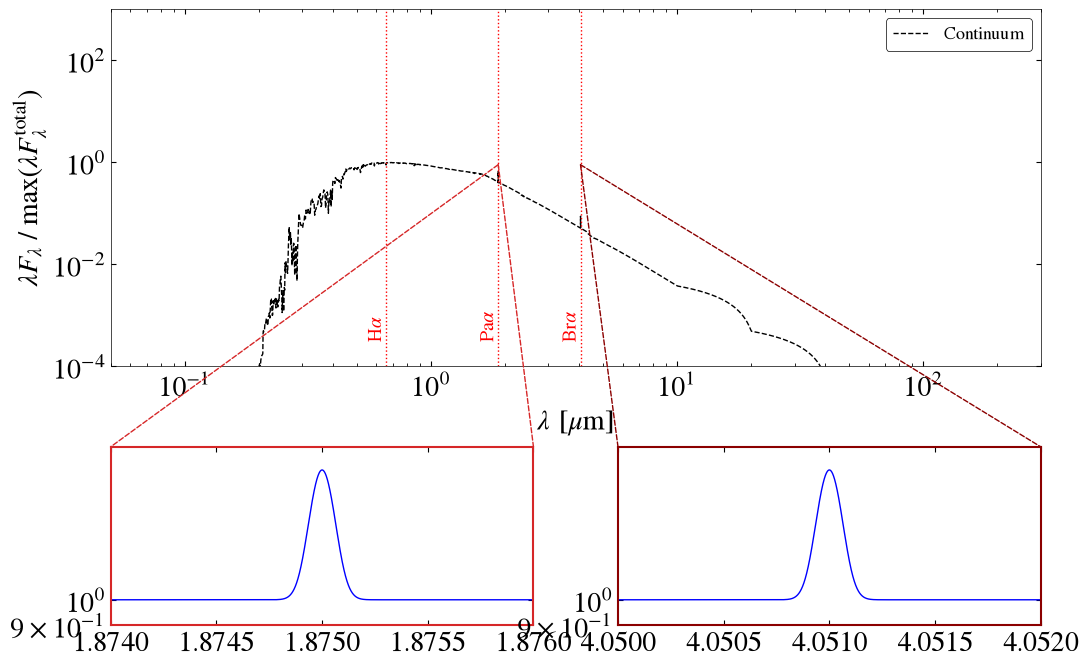

In [53]:
SPEC.Plot_spectrum_modeled_source()

### Checking $\Delta m $ as function of $W_{\mathrm{eq}}$ for a given continuum

In [88]:
filters_pa = ["F187N", "F115W", "F200W"]
filters_br = ["F405N", "F335M", "F356W", "F410M", "F444W", "F480M"]
N_W_eq = 100
continuum_mode = "Bessel"

Weqs, MAGS_per_filter_pa = SSt.Compute_delta_m_weq(
    lam0=SSt.wave_pa_alpha.to(u.AA),
    filters=filters_pa,
    N_W_eq=N_W_eq,
    continuum_mode=continuum_mode,
)

Weqs, MAGS_per_filter_br = SSt.Compute_delta_m_weq(
    lam0=SSt.wave_br_alpha.to(u.AA),
    filters=filters_br,
    N_W_eq=N_W_eq,
    continuum_mode=continuum_mode,
)

Computing ∆m(W_eq): 100%|██████████| 100/100 [00:17<00:00,  5.59it/s]


#### $Pa \alpha$ plots

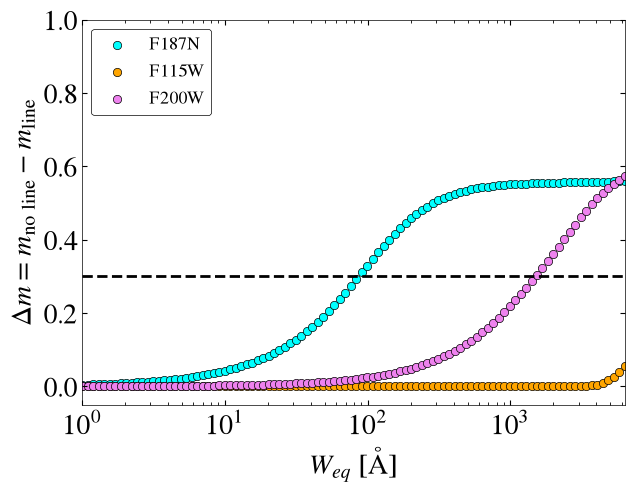

In [81]:
mag_diff_dic_pa = {}
colors = [
    "cyan",
    "orange",
    "violet",
]
for F_idx, FILT in enumerate(filters_pa):
    mag_diff_dic_pa[FILT] = (
        MAGS_per_filter_pa[F_idx, 0] - MAGS_per_filter_pa[F_idx, 1],
        colors[F_idx],
    )

SSt.Plot_delta_m_weq(
    Weqs,
    mag_diff_dic=mag_diff_dic_pa,
)

#### $Br \alpha$ plots

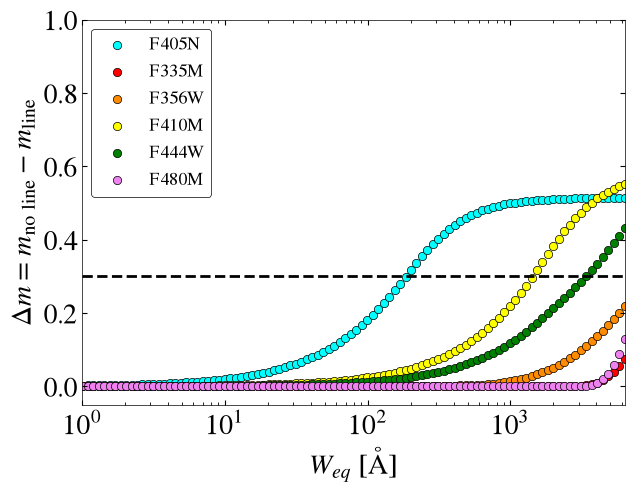

In [86]:
mag_diff_dic_br = {}
colors = [
    "cyan",
    "red",
    "darkorange",
    "yellow",
    "green",
    "violet",
]

for F_idx, FILT in enumerate(filters_br):
    mag_diff_dic_br[FILT] = (
        MAGS_per_filter_br[F_idx, 0] - MAGS_per_filter_br[F_idx, 1],
        colors[F_idx],
    )

SSt.Plot_delta_m_weq(
    Weqs,
    mag_diff_dic=mag_diff_dic_br,
)

#### Impact of the continuum filters